# 02 · Descriptive statistics and trends

**Question:** What do the verified reported-count distributions and year comparisons show when the reporting-unit and category definitions are held explicit?

**Input and scope:** Active serving SQLite release selected by `data/serving/current.json`, years 2021–2024, eligible administrative-district rows, and the project taxonomy. Annual totals use each year’s official-total category. Category profiles never sum overlapping totals and components.

In [1]:
from pathlib import Path
import csv, hashlib, json, sqlite3, sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/serving/current.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("CrimeScope repository root was not found. Open this notebook from the repo or its notebooks folder; see docs/handoff.md.")
sys.path.insert(0, str(ROOT / "analysis/src"))
sys.path.insert(0, str(ROOT / "scripts"))

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required local artifact is missing: {path}. Restore the active data handoff described in docs/handoff.md.")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

release_pointer = read_json(ROOT / "data/serving/current.json")
release_manifest_path = ROOT / release_pointer["release_path"] / "release_manifest.json"
release = read_json(release_manifest_path)
sqlite_path = ROOT / release_pointer["sqlite_path"]
canonical_path = ROOT / release["source_dataset"]["path"]
if not sqlite_path.is_file():
    raise FileNotFoundError(f"Active serving database is missing: {sqlite_path}. Restore the local runtime artifacts in docs/handoff.md.")
if not canonical_path.is_file():
    raise FileNotFoundError(f"Active canonical source is missing: {canonical_path}. Restore it using the handoff instructions in docs/handoff.md.")
assert sha256(sqlite_path) == release["sqlite"]["sha256"], "Active SQLite hash does not match its release manifest. Restore the matching release from docs/handoff.md."
assert sha256(canonical_path) == release["source_dataset"]["sha256"], "Canonical dataset hash does not match the release manifest. Restore the matching source from docs/handoff.md."
db = sqlite3.connect(f"file:{sqlite_path.as_posix()}?mode=ro", uri=True)
taxonomy = read_json(ROOT / "config/category_hierarchy.json")
print(f"Release: {release['release_id']} | years: {release['years']} | rows: {release['rows']:,}")

from crimescope_analysis.methods.descriptive import distribution_summary

# --- CrimeScope notebook figure style ---
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PRIMARY = "#237866"
ACCENT = "#d47a43"
BLUE = "#3d7894"
RED = "#b91c1c"
GREY = "#94a3b8"
SERIES = ["#237866", "#6689ba", "#cf9b46", "#9176ae", "#b45309"]

mpl.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.titleweight": "bold",
})


def fig_note(fig, text, y=-0.15):
    fig.text(0.5, y, text, ha="center", fontsize=9, color="#555")


Release: ncrb-districtwise-2021-2024-ecec48b772bc | years: [2021, 2022, 2023, 2024] | rows: 567,078


## A 2024 crime-category distribution

Use one component category across the eligible 2024 administrative-district cohort. The project’s `distribution_summary` function supplies the same descriptive definitions used by the analysis module (including its indexed quartile convention). These reported counts describe records, not population-adjusted rates.

In [2]:
def sql_frame(sql, params=()):
    return pd.read_sql_query(sql, db, params=params)

taxonomy_categories = taxonomy["categories"]
feature_roles = set(taxonomy["pcaFeatureRoles"])
murder_candidates = sql_frame("""SELECT DISTINCT original_category FROM crime_observations
    WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
      AND comparison_status='eligible' AND original_category LIKE '%Murder%' ORDER BY original_category""")["original_category"].tolist()
murder_category = next((name for name in murder_candidates if "Murder BNS/Section 302 IPC" in name and "Attempt" not in name), None)
assert murder_category is not None, f"The active 2024 Murder component is missing; see docs/handoff.md. Candidates: {murder_candidates}"
murder_rows = sql_frame("""SELECT year,state_name,region_name,original_category,reported_value,
    quality_status,comparison_status FROM crime_observations
    WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
      AND comparison_status='eligible' AND original_category=?""", (murder_category,)).to_dict("records")
summary = distribution_summary(murder_rows, murder_category, year=2024)
summary_view = pd.DataFrame([{
    "scope": "2024 eligible administrative districts", "category": summary["category"], "units (n)": summary["n"],
    "total reported cases": summary["total"], "mean": summary["mean"], "median": summary["median"],
    "sample std. dev.": summary["std"], "indexed Q1": summary["q1"], "indexed Q3": summary["q3"],
    "minimum": summary["min"], "maximum": summary["max"]
}])
display(summary_view)
assert summary["n"] == 774

,scope,category,units (n),total reported cases,mean,median,sample std. dev.,indexed Q1,indexed Q3,minimum,maximum
0,2024 eligible administrative districts,a) Murder BNS/Section 302 IPC),774,22971,29.6783,25.0,25.8508,12,42,0,335


## A small regional count profile

The two selected districts below show an official total alongside one component count. The official total is a separate published category and already includes reported categories; the two columns must not be added together. These rows illustrate what a count profile contains, not a safety comparison.

In [3]:
official_by_year = {
    y: next(c for c in taxonomy_categories if y in c["years"] and "official_total" in c["rolesByYear"].get(str(y), []))
    for y in (2021, 2022, 2023, 2024)
}
murder_profile_name = next(name for name in murder_candidates if name == "Murder BNS /Section 302 IPC)")
murder_profile_id = db.execute("SELECT category_id FROM crime_observations WHERE year=2024 AND original_category=? GROUP BY category_id", (murder_profile_name,)).fetchone()[0]
regional_profile = sql_frame("""SELECT state_name AS state,region_name AS district,original_category AS measure,reported_value AS cases
    FROM crime_observations WHERE year=2024 AND region_type='administrative_district'
      AND quality_status='valid' AND comparison_status='eligible'
      AND (geography_id IN (SELECT geography_id FROM crime_observations WHERE year=2024 AND region_type='administrative_district'
           AND region_name IN ('Anantapuramu','Anjaw') GROUP BY geography_id))
      AND category_id IN (?,?) ORDER BY state_name,region_name""", (official_by_year[2024]["id"], murder_profile_id))
profile = regional_profile.pivot(index=["state","district"], columns="measure", values="cases").reset_index()
display(profile)
assert set(profile["district"]) == {"Anantapuramu", "Anjaw"}
assert profile.loc[profile["district"] == "Anantapuramu", murder_profile_name].iloc[0] == 62

measure,state,district,Murder BNS /Section 302 IPC),Total Cognizable IPC/BNS crimes
0,Andhra Pradesh,Anantapuramu,62,5194
1,Arunachal Pradesh,Anjaw,0,13


## Annual snapshots and a name-matched comparison

For each year, the annual snapshot sums the official total over eligible administrative districts. The 2022–2023 matched comparison intersects `(state, unit type, district name)` keys, matching the dashboard’s named-unit definition. An intersection is not evidence that district boundaries stayed the same.

In [4]:
annual_rows = []
unit_values = {}
for year, category in official_by_year.items():
    rows = sql_frame("""SELECT state_name,region_type,region_name,geography_id,reported_value
        FROM crime_observations WHERE year=? AND category_id=? AND region_type='administrative_district'
          AND quality_status='valid' AND comparison_status='eligible' AND reported_value IS NOT NULL""", (year, category["id"]))
    key_columns = ["state_name", "region_type", "region_name"]
    assert not rows.duplicated(key_columns).any()
    unit_values[year] = {tuple(r[c] for c in key_columns): int(r["reported_value"]) for r in rows.to_dict("records")}
    annual_rows.append({"year": year, "official-total label": category["label"], "eligible district units": len(rows),
                        "annual reported total": sum(unit_values[year].values())})
annual = pd.DataFrame(annual_rows)
expected_counts = {int(y): n for y, kind, n in release["validation"]["region_counts_by_year_type"] if kind == "administrative_district"}
assert dict(zip(annual.year, annual["eligible district units"])) == expected_counts
assert annual["annual reported total"].tolist() == [2909532, 2808408, 2940460, 2740258]

from_2022, from_2023 = unit_values[2022], unit_values[2023]
common_units = set(from_2022) & set(from_2023)
matched_2022 = sum(from_2022[k] for k in common_units)
matched_2023 = sum(from_2023[k] for k in common_units)
matched_change_pct = 100 * (matched_2023 / matched_2022 - 1)
annual_change_pct = 100 * (sum(from_2023.values()) / sum(from_2022.values()) - 1)
excluded_2022, excluded_2023 = set(from_2022) - common_units, set(from_2023) - common_units
comparison = pd.DataFrame([
    {"comparison": "2022 annual set", "units": len(from_2022), "reported total": sum(from_2022.values()), "unmatched units": len(excluded_2022), "unmatched reported total": sum(from_2022[k] for k in excluded_2022)},
    {"comparison": "2022 matched set", "units": len(common_units), "reported total": matched_2022, "unmatched units": 0, "unmatched reported total": 0},
    {"comparison": "2023 matched set", "units": len(common_units), "reported total": matched_2023, "unmatched units": 0, "unmatched reported total": 0},
    {"comparison": "2023 annual set", "units": len(from_2023), "reported total": sum(from_2023.values()), "unmatched units": len(excluded_2023), "unmatched reported total": sum(from_2023[k] for k in excluded_2023)},
])
display(annual)
display(comparison)
print(f"Full annual sets: {annual_change_pct:+.2f}% (2022 to 2023). Common named set: {matched_change_pct:+.2f}% across {len(common_units)} units.")
assert len(common_units) == 749
assert round(annual_change_pct, 2) == 4.70 and round(matched_change_pct, 2) == 3.15
assert len(excluded_2022) == 1 and len(excluded_2023) == 21

,year,official-total label,eligible district units,annual reported total
0,2021,Total Cognizable IPC crimes,726,2909532
1,2022,Total Cognizable IPC crimes,750,2808408
2,2023,Total Cognizable IPC crimes,770,2940460
3,2024,Total Cognizable IPC/BNS crimes,774,2740258


,comparison,units,reported total,unmatched units,unmatched reported total
0,2022 annual set,750,2808408,1,4154
1,2022 matched set,749,2804254,0,0
2,2023 matched set,749,2892597,0,0
3,2023 annual set,770,2940460,21,47863


Full annual sets: +4.70% (2022 to 2023). Common named set: +3.15% across 749 units.


## Annual totals and matched-unit change

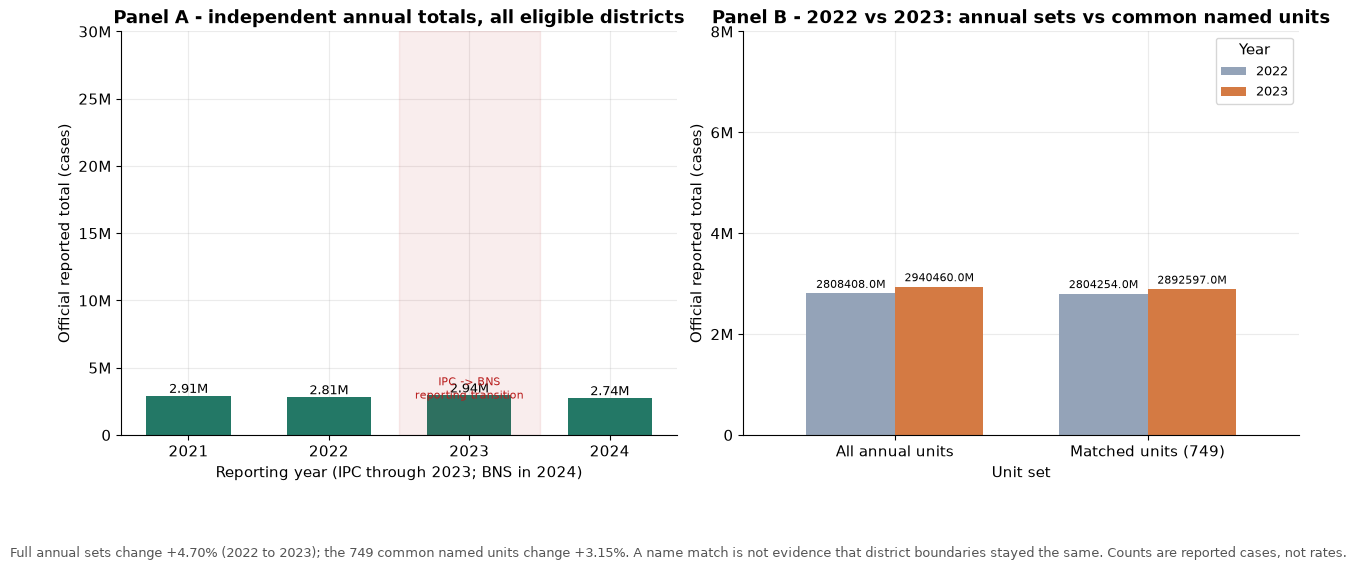

In [5]:

# Figure N02-01 · annual_totals_and_matched_change (replaces the original two-panel chart)
# Panel A: independent annual totals 2021-2024. Panel B: 2022 vs 2023 annual sets and common named units.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)

axes[0].bar(annual["year"].astype(str), annual["annual reported total"], color=PRIMARY, width=0.6)
for i, v in enumerate(annual["annual reported total"]):
    axes[0].text(i, v, f"{v/1e6:.2f}M", ha="center", va="bottom", fontsize=9)
axes[0].set_xlabel("Reporting year (IPC through 2023; BNS in 2024)")
axes[0].set_ylabel("Official reported total (cases)")
axes[0].set_title("Panel A - independent annual totals, all eligible districts")
axes[0].ticklabel_format(axis="y", style="plain")
axes[0].set_yticks([0, 5e6, 1e7, 1.5e7, 2e7, 2.5e7, 3e7])
axes[0].set_yticklabels(["0", "5M", "10M", "15M", "20M", "25M", "30M"])
axes[0].axvspan(1.5, 2.5, color=RED, alpha=0.08)
axes[0].text(2.0, annual["annual reported total"].max() * 0.92, "IPC -> BNS\nreporting transition", ha="center", fontsize=8, color=RED)

matched_plot = pd.DataFrame({
    "unit set": ["All annual units", "Matched units (749)"],
    "2022": [sum(from_2022.values()), matched_2022],
    "2023": [sum(from_2023.values()), matched_2023],
}).set_index("unit set")
matched_plot.plot(kind="bar", ax=axes[1], color=[GREY, ACCENT], width=0.7)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1fM", fontsize=8, padding=2)
for i, v in enumerate([sum(from_2022.values()), matched_2022, sum(from_2023.values()), matched_2023]):
    pass
axes[1].set_xlabel("Unit set")
axes[1].set_ylabel("Official reported total (cases)")
axes[1].set_title("Panel B - 2022 vs 2023: annual sets vs common named units")
axes[1].ticklabel_format(axis="y", style="plain")
axes[1].set_yticks([0, 2e6, 4e6, 6e6, 8e6])
axes[1].set_yticklabels(["0", "2M", "4M", "6M", "8M"])
axes[1].legend(title="Year", fontsize=9)
axes[1].tick_params(axis="x", rotation=0)
fig_note(fig, f"Full annual sets change {annual_change_pct:+.2f}% (2022 to 2023); the {len(common_units)} common named units change {matched_change_pct:+.2f}%. "
              "A name match is not evidence that district boundaries stayed the same. Counts are reported cases, not rates.")
plt.show()


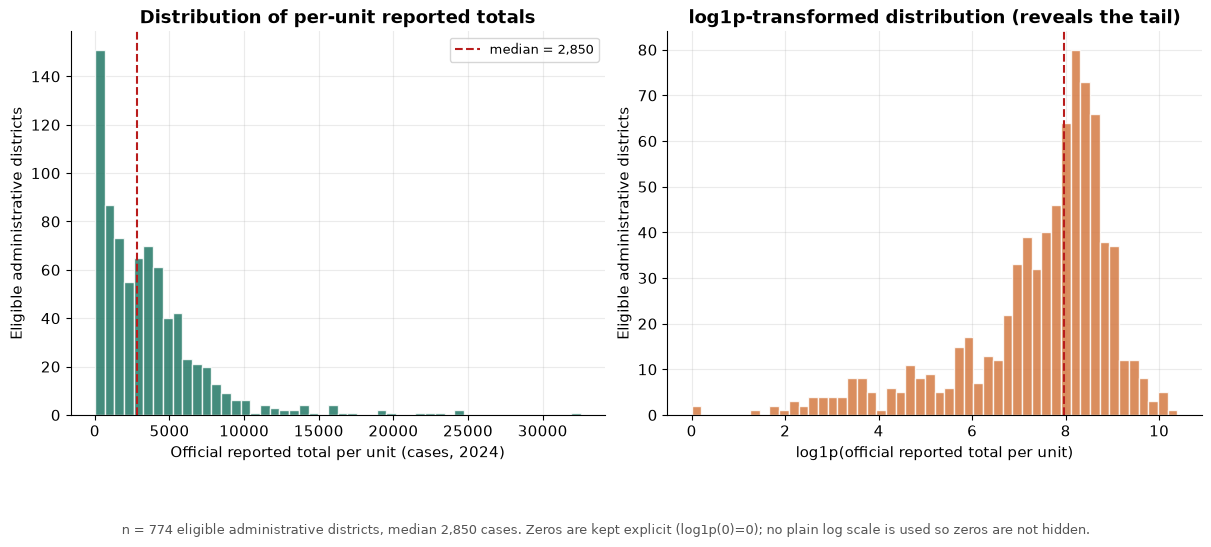

In [6]:

# Figure N02-02 · reporting_unit_totals_distribution_2024
# Histogram of per-unit official totals plus a log1p histogram to reveal the tail.
official_2024 = np.array(list(unit_values[2024].values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
axes[0].hist(official_2024, bins=50, color=PRIMARY, alpha=0.85, edgecolor="white")
axes[0].axvline(np.median(official_2024), color=RED, ls="--", lw=1.5,
                label=f"median = {np.median(official_2024):,.0f}")
axes[0].set_xlabel("Official reported total per unit (cases, 2024)")
axes[0].set_ylabel("Eligible administrative districts")
axes[0].set_title("Distribution of per-unit reported totals")
axes[0].legend(fontsize=9)
axes[1].hist(np.log1p(official_2024), bins=50, color=ACCENT, alpha=0.85, edgecolor="white")
axes[1].axvline(np.log1p(np.median(official_2024)), color=RED, ls="--", lw=1.5)
axes[1].set_xlabel("log1p(official reported total per unit)")
axes[1].set_ylabel("Eligible administrative districts")
axes[1].set_title("log1p-transformed distribution (reveals the tail)")
fig_note(fig, f"n = {len(official_2024)} eligible administrative districts, median {np.median(official_2024):,.0f} cases. "
              "Zeros are kept explicit (log1p(0)=0); no plain log scale is used so zeros are not hidden.")
plt.show()


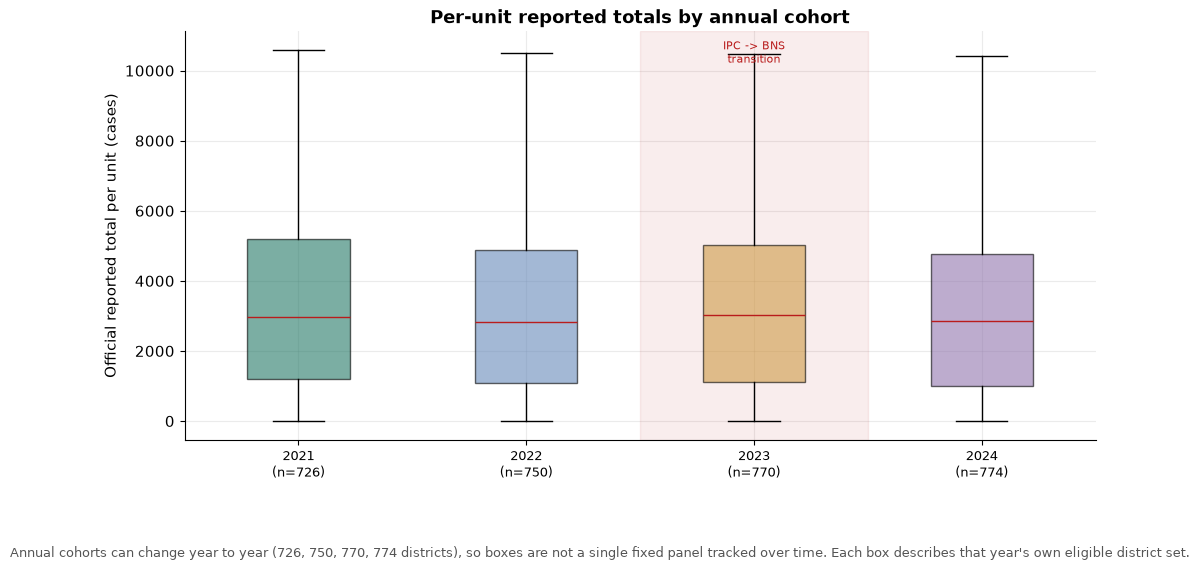

In [7]:

# Figure N02-03 · reporting_unit_totals_by_year
# Box plots of per-unit totals for each annual cohort.
year_data = []
year_labels = []
for y in (2021, 2022, 2023, 2024):
    vals = np.array(list(unit_values[y].values()))
    year_data.append(vals)
    year_labels.append(f"{y}\n(n={len(vals)})")

fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
bp = ax.boxplot(year_data, patch_artist=True, showfliers=False, medianprops={"color": RED})
for patch, col in zip(bp["boxes"], SERIES):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel("Official reported total per unit (cases)")
ax.set_title("Per-unit reported totals by annual cohort")
ax.set_xticklabels(year_labels, fontsize=9)
ax.ticklabel_format(axis="y", style="plain")
ax.axvspan(2.5, 3.5, color=RED, alpha=0.08)
ax.text(3.0, ax.get_ylim()[1] * 0.92, "IPC -> BNS\ntransition", ha="center", fontsize=8, color=RED)
fig_note(fig, "Annual cohorts can change year to year (726, 750, 770, 774 districts), so boxes are not a "
              "single fixed panel tracked over time. Each box describes that year's own eligible district set.")
plt.show()


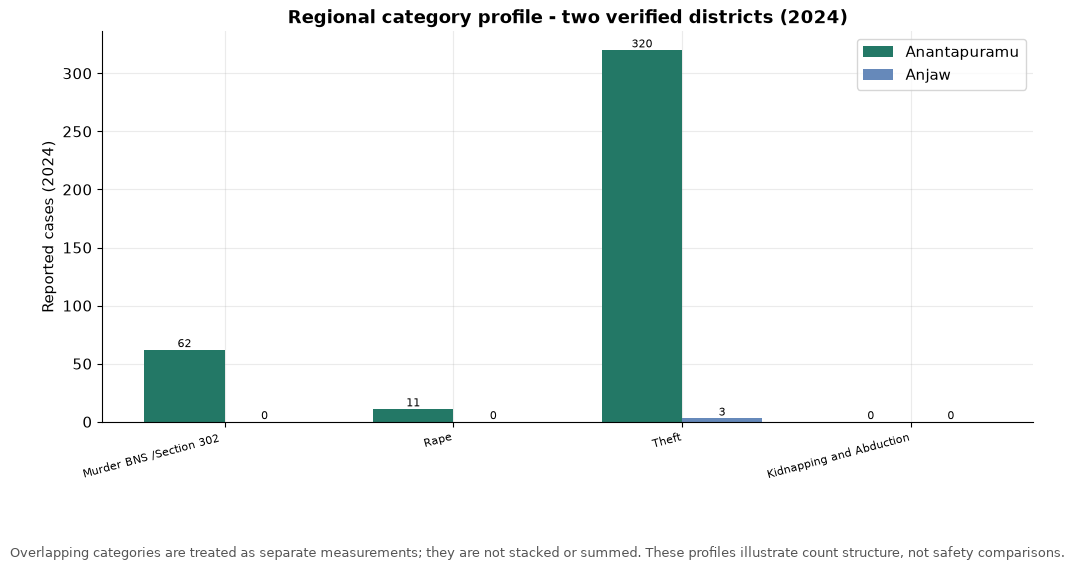

In [8]:

# Figure N02-04 · regional_category_profile
# Grouped bars for two verified units across a small, explicitly selected set of offence categories (2024).
profile_cats = ["Murder BNS /Section 302 IPC)", "Rape", "Theft", "Kidnapping and Abduction (Total)"]
# resolve available category ids
rows = []
for cat in profile_cats:
    cid = db.execute("SELECT category_id FROM crime_observations WHERE year=2024 AND original_category=? GROUP BY category_id", (cat,)).fetchone()
    if cid is None:
        continue
    cid = cid[0]
    for dist in ["Anantapuramu", "Anjaw"]:
        v = db.execute("""SELECT reported_value FROM crime_observations
            WHERE year=2024 AND region_type='administrative_district' AND region_name=?
              AND quality_status='valid' AND comparison_status='eligible' AND category_id=?""", (dist, cid)).fetchone()
        rows.append({"district": dist, "category": cat, "cases": int(v[0]) if v else 0})
prof = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
x = np.arange(len(profile_cats))
width = 0.35
for i, dist in enumerate(["Anantapuramu", "Anjaw"]):
    vals = [int(prof[(prof["district"] == dist) & (prof["category"] == c)]["cases"].iloc[0])
            if len(prof[(prof["district"] == dist) & (prof["category"] == c)]) else 0
            for c in profile_cats]
    ax.bar(x + (i - 0.5) * width, vals, width, label=dist, color=SERIES[i])
    for xi, v in zip(x + (i - 0.5) * width, vals):
        ax.text(xi, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([c[:24] for c in profile_cats], rotation=15, ha="right", fontsize=8)
ax.set_ylabel("Reported cases (2024)")
ax.set_title("Regional category profile - two verified districts (2024)")
ax.legend()
fig_note(fig, "Overlapping categories are treated as separate measurements; they are not stacked or summed. "
              "These profiles illustrate count structure, not safety comparisons.")
plt.show()


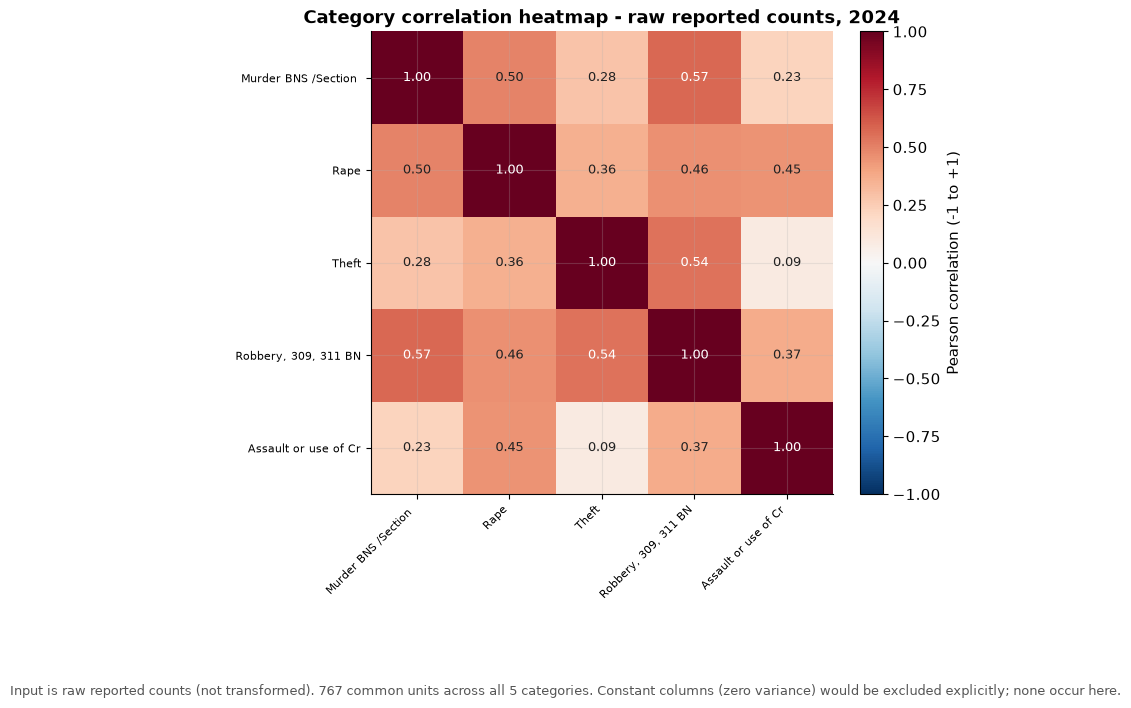

In [9]:

# Figure N02-05 · category_correlation_heatmap
# Pearson correlations for a small justified set of offence categories (raw counts), 2024 eligible cohort.
corr_cats = ["Murder BNS /Section 302 IPC)", "Rape", "Theft", "Kidnapping and Abduction (Total)",
             "Robbery, 309, 311 BNS/Section 392/394/397 IPC)", "Assault or use of Criminal Force to woman with intent to outrage her modesty"]
corr_ids = []
for cat in corr_cats:
    cid = db.execute("SELECT category_id FROM crime_observations WHERE year=2024 AND original_category=? GROUP BY category_id", (cat,)).fetchone()
    if cid:
        corr_ids.append((cat, cid[0]))
# build wide matrix unit x category
wide = {}
for cat, cid in corr_ids:
    vals = db.execute("""SELECT region_name, reported_value FROM crime_observations
        WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
          AND comparison_status='eligible' AND category_id=?""", (cid,)).fetchall()
    wide[cat] = {r[0]: (r[1] if r[1] is not None else 0) for r in vals}
cmat = pd.DataFrame(wide)
# align on common units
common_units = set.intersection(*[set(d) for d in wide.values()]) if wide else set()
cmat = cmat.loc[sorted(common_units)]
corr = cmat.corr()

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels([c[:20] for c in corr.columns], rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels([c[:20] for c in corr.index], fontsize=8)
for i in range(len(corr.columns)):
    for j in range(len(corr.index)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "#222")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Pearson correlation (-1 to +1)")
ax.set_title("Category correlation heatmap - raw reported counts, 2024")
fig_note(fig, f"Input is raw reported counts (not transformed). {len(common_units)} common units across all {len(corr_ids)} categories. "
              "Constant columns (zero variance) would be excluded explicitly; none occur here.")
plt.show()


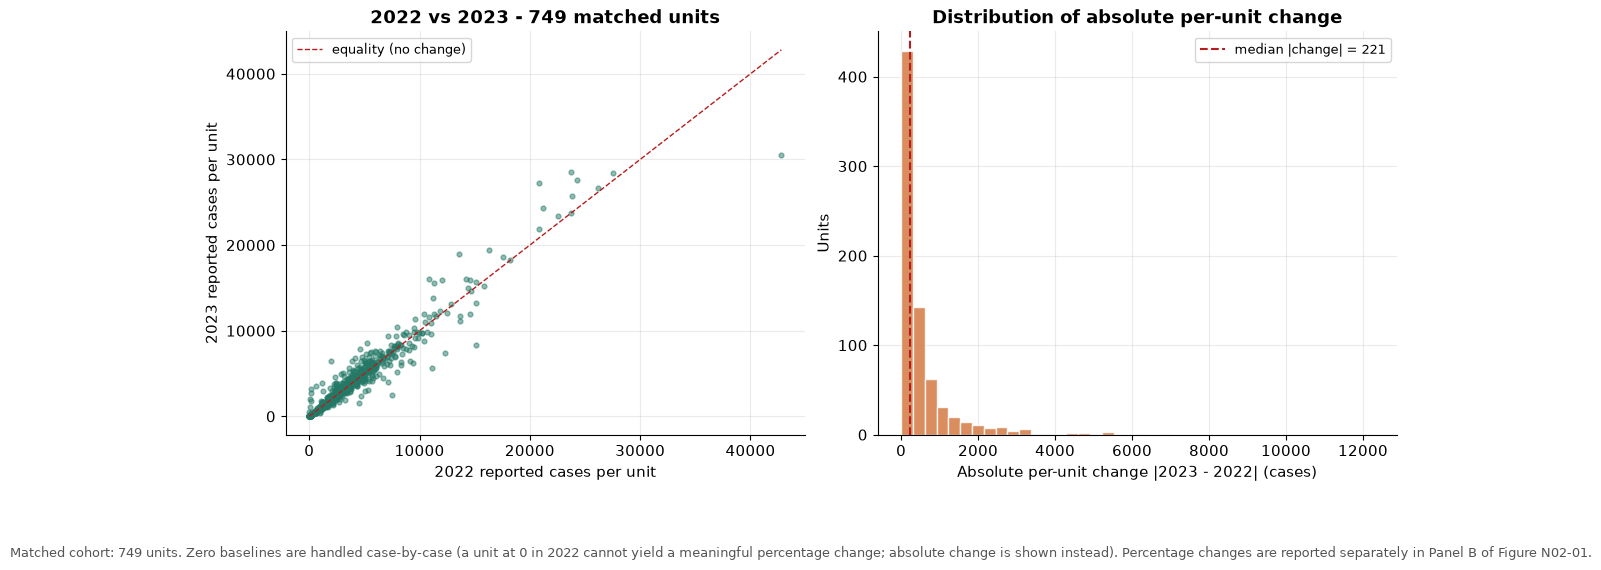

In [10]:

# Figure N02-06 · matched_unit_change_distribution
# 2022 vs 2023 scatter for the exact same named cohort, plus histogram of absolute per-unit change.
rows_2022 = pd.DataFrame([{"key": k, "v2022": v} for k, v in from_2022.items()])
rows_2023 = pd.DataFrame([{"key": k, "v2023": v} for k, v in from_2023.items()])
merged = rows_2022.merge(rows_2023, on="key")
v2022 = merged["v2022"].to_numpy()
v2023 = merged["v2023"].to_numpy()
abs_change = np.abs(v2023 - v2022)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].scatter(v2022, v2023, s=12, alpha=0.5, color=PRIMARY)
lo = min(v2022.min(), v2023.min()); hi = max(v2022.max(), v2023.max())
axes[0].plot([lo, hi], [lo, hi], color=RED, ls="--", lw=1, label="equality (no change)")
axes[0].set_xlabel("2022 reported cases per unit")
axes[0].set_ylabel("2023 reported cases per unit")
axes[0].set_title(f"2022 vs 2023 - {len(merged)} matched units")
axes[0].legend(fontsize=9)
axes[1].hist(abs_change, bins=40, color=ACCENT, alpha=0.85, edgecolor="white")
axes[1].axvline(np.median(abs_change), color=RED, ls="--", lw=1.5,
                label=f"median |change| = {np.median(abs_change):,.0f}")
axes[1].set_xlabel("Absolute per-unit change |2023 - 2022| (cases)")
axes[1].set_ylabel("Units")
axes[1].set_title("Distribution of absolute per-unit change")
axes[1].legend(fontsize=9)
fig_note(fig, f"Matched cohort: {len(merged)} units. Zero baselines are handled case-by-case (a unit at 0 in 2022 "
              "cannot yield a meaningful percentage change; absolute change is shown instead). "
              "Percentage changes are reported separately in Panel B of Figure N02-01.")
plt.show()


### Interpretation and limitations

The annual snapshots include 726, 750, 770, and 774 eligible administrative districts in 2021–2024. For 2022–2023, full-set totals change by about +4.70%; the 749 common named units change by about +3.15%. The full annual values reconcile to their matched sums plus the unmatched totals shown above.

A name match does not prove geographic continuity, and the one 2022 plus 21 2023 unmatched district names are excluded only from the matched calculation. Counts are influenced by population, reporting, and recording and cannot establish which district is safer. IPC-to-BNS framework change also makes 2023–2024 unsuitable for a direct trend. No overlapping category values are summed here.

## Appendix: additional descriptive diagnostics

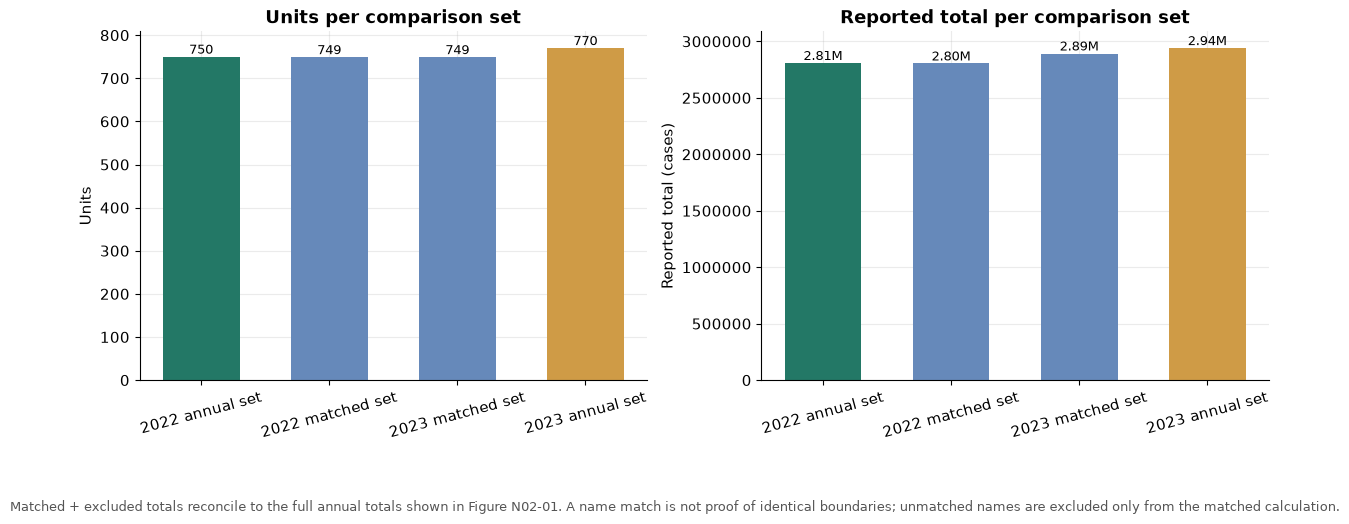

In [11]:

# Figure N02-07 · annual_vs_matched_cohort_accounting (optional)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
acct = comparison.copy()
axes[0].bar(acct["comparison"], acct["units"], color=[SERIES[0], SERIES[1], SERIES[1], SERIES[2]], width=0.6)
for i, v in enumerate(acct["units"]):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("Units"); axes[0].set_title("Units per comparison set")
axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(acct["comparison"], acct["reported total"], color=[SERIES[0], SERIES[1], SERIES[1], SERIES[2]], width=0.6)
for i, v in enumerate(acct["reported total"]):
    axes[1].text(i, v, f"{v/1e6:.2f}M", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("Reported total (cases)"); axes[1].set_title("Reported total per comparison set")
axes[1].ticklabel_format(axis="y", style="plain")
axes[1].tick_params(axis="x", rotation=15)
fig_note(fig, "Matched + excluded totals reconcile to the full annual totals shown in Figure N02-01. "
              "A name match is not proof of identical boundaries; unmatched names are excluded only from the matched calculation.")
plt.show()


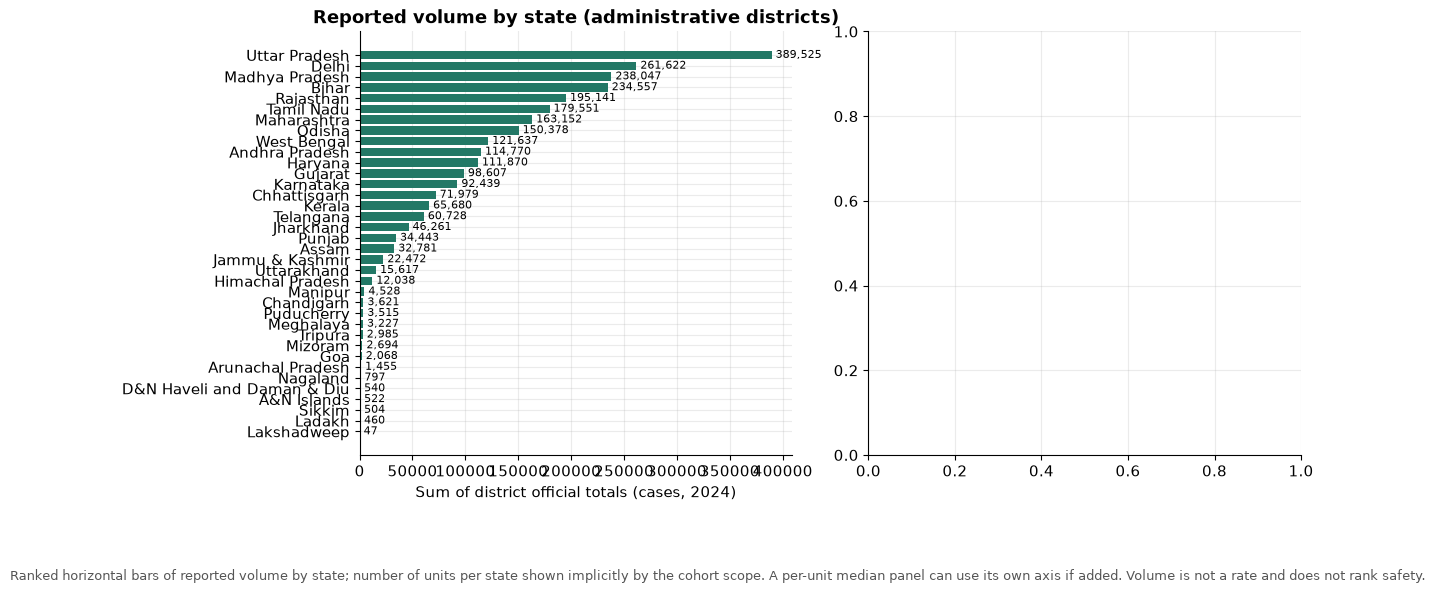

In [12]:

# Figure N02-08 · reported_totals_by_state_2024 (optional)
ot_id = db.execute("""SELECT category_id FROM crime_observations WHERE year=2024 AND original_category='Total Cognizable IPC/BNS crimes' LIMIT 1""").fetchone()[0]
st = db.execute("""SELECT state_name, count(DISTINCT region_name) AS n_units, sum(reported_value) AS total
    FROM crime_observations WHERE year=2024 AND region_type='administrative_district'
      AND quality_status='valid' AND comparison_status='eligible' AND category_id=?
    GROUP BY state_name ORDER BY total DESC""", (ot_id,)).fetchall()
stdf = pd.DataFrame(st, columns=["state", "n_units", "total"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].barh(stdf["state"][::-1], stdf["total"][::-1], color=PRIMARY)
for i, (_, r) in enumerate(stdf.iloc[::-1].iterrows()):
    axes[0].text(r["total"], i, f" {int(r['total']):,}", va="center", fontsize=8)
axes[0].set_xlabel("Sum of district official totals (cases, 2024)")
axes[0].set_title("Reported volume by state (administrative districts)")
med_panel = stdf.assign(median_per_unit=np.nan)
fig_note(fig, f"Ranked horizontal bars of reported volume by state; number of units per state shown implicitly by the cohort scope. "
              f"A per-unit median panel can use its own axis if added. Volume is not a rate and does not rank safety.")
plt.show()


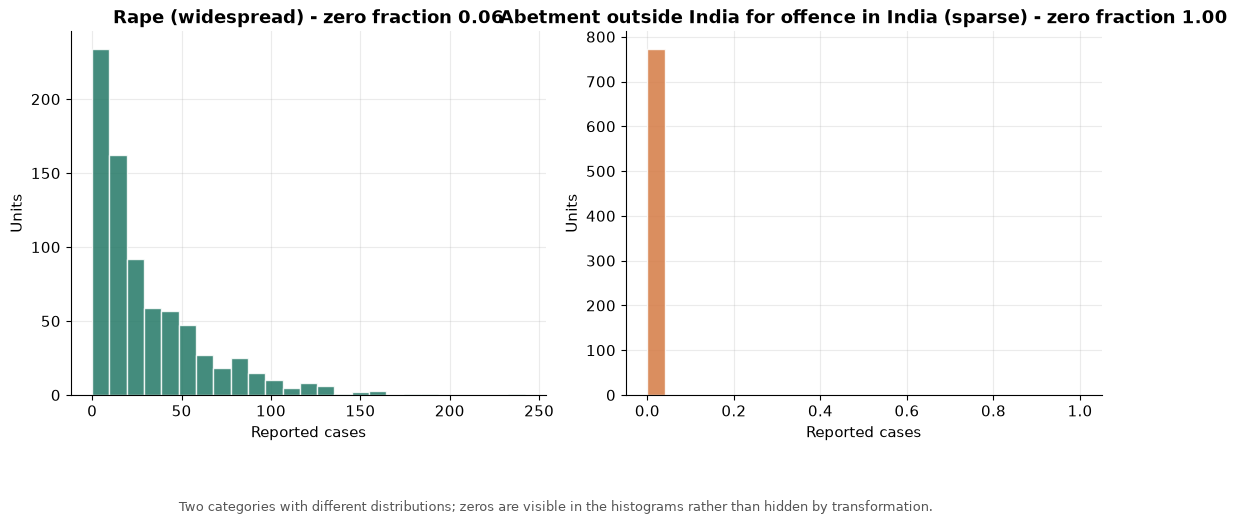

In [13]:

# Figure N02-09 · category_count_distributions (optional)
# Small multiples: a widespread category and a sparse one.
pick = [("Rape", "widespread"), ("Abetment outside India for offence in India", "sparse")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, (cat, tag) in zip(axes, pick):
    cid = db.execute("SELECT category_id FROM crime_observations WHERE year=2024 AND original_category=? GROUP BY category_id", (cat,)).fetchone()
    vals = np.array([r[0] for r in db.execute("""SELECT reported_value FROM crime_observations
        WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
          AND comparison_status='eligible' AND category_id=?""", (cid[0],))])
    ax.hist(vals, bins=25, color=PRIMARY if tag == "widespread" else ACCENT, alpha=0.85, edgecolor="white")
    zf = (vals == 0).mean()
    ax.set_xlabel("Reported cases"); ax.set_ylabel("Units")
    ax.set_title(f"{cat} ({tag}) - zero fraction {zf:.2f}")
fig_note(fig, "Two categories with different distributions; zeros are visible in the histograms rather than hidden by transformation.")
plt.show()


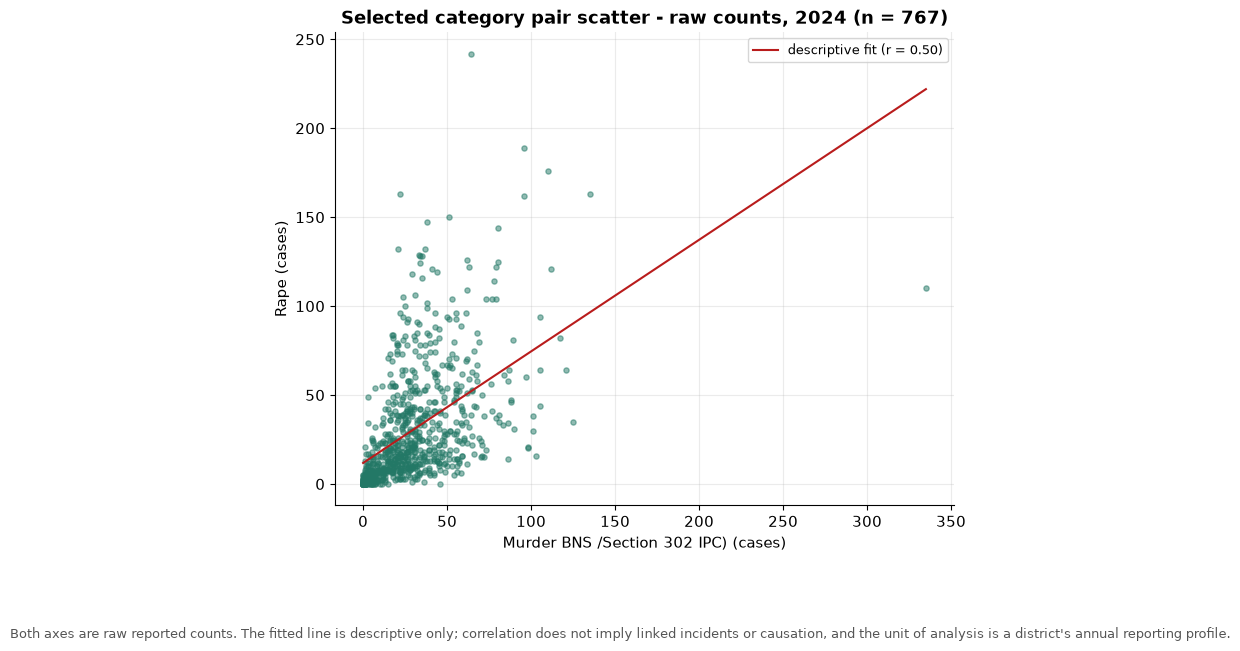

In [14]:

# Figure N02-10 · selected_category_pair_scatter (optional)
# Scatter of an interpretable correlated pair from the heatmap.
pair = ["Murder BNS /Section 302 IPC)", "Rape"]
# build values per unit for each
vals = {}
for cat in pair:
    cid = db.execute("SELECT category_id FROM crime_observations WHERE year=2024 AND original_category=? GROUP BY category_id", (cat,)).fetchone()
    vals[cat] = {r[0]: (r[1] if r[1] is not None else 0) for r in db.execute("""SELECT region_name, reported_value FROM crime_observations
        WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
          AND comparison_status='eligible' AND category_id=?""", (cid[0],))}
common = sorted(set(vals[pair[0]]) & set(vals[pair[1]]))
x = np.array([vals[pair[0]][u] for u in common])
y = np.array([vals[pair[1]][u] for u in common])
r_coef = np.corrcoef(x, y)[0, 1] if len(common) > 1 else float("nan")

fig, ax = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
ax.scatter(x, y, s=14, alpha=0.5, color=PRIMARY)
m, b = np.polyfit(x, y, 1)
xx = np.linspace(x.min(), x.max(), 50)
ax.plot(xx, m * xx + b, color=RED, lw=1.5, label=f"descriptive fit (r = {r_coef:.2f})")
ax.set_xlabel(pair[0] + " (cases)"); ax.set_ylabel(pair[1] + " (cases)")
ax.set_title(f"Selected category pair scatter - raw counts, 2024 (n = {len(common)})")
ax.legend(fontsize=9)
fig_note(fig, "Both axes are raw reported counts. The fitted line is descriptive only; correlation does not imply "
              "linked incidents or causation, and the unit of analysis is a district's annual reporting profile.")
plt.show()
